# COMP8240 — Reproducing BERTopic: constructed news dataset (v2) pipeline

Runs every step the final report needs for the **newly constructed dataset**, in order,
on your own collected articles, and writes all numbers, tables and figures to
`results/v2/report/` (see `REPORT_NUMBERS.md` there).

**Before you start**
1. *Runtime → Change runtime type → T4 GPU.*
2. Put your project folder on Google Drive (e.g. `MyDrive/COMP8240_project`) containing:
   - `src/` — **the updated scripts from this package** (copy them over your old ones),
   - `ANNOTATION_GUIDE.md`,
   - `data/v2/articles_raw.csv` and `data/v2/collection_log.csv` (from your daily collection),
   - optionally `results/constructed_dataset_assignments.csv` (v1 result, shown as a reference row).
3. Run the cells top to bottom. The notebook **stops at Step 3** so you can label events;
   come back and continue from Step 4 once the sheets are labelled.

Steps: 1 setup · 2 preprocess · 3 annotation sheets (manual labelling) · 4 agreement ·
5 BERTopic sweep · 6 LDA baseline · 7 events-vs-outlets evaluation · 8 LLM-as-judge ·
9 report tables · 10 (optional) refresh replication numbers · 11 download results

## 1 · Setup

In [2]:
# ---- settings -------------------------------------------------------------
PROJECT_DIR = "/content/drive/MyDrive/COMP8240_project"   # folder with src/ and data/v2/
START, END = None, None        # optional date window for the dataset, e.g. "2026-10-10", "2026-11-05"
SEEDS = [1, 2, 3]              # the paper averages 3 runs
MAIN_MTS = 5                   # main min_topic_size; 3 and 10 are run once as a sensitivity check
RUN_MPNET = True               # also run the paper's embedding model (all-mpnet-base-v2) on capped text
JUDGE_PROVIDER = "hf"          # "hf" = free open model on the Colab GPU; "anthropic" needs ANTHROPIC_API_KEY
OFFLINE_TEST = False           # True = fast pipeline test with a TF-IDF stand-in + mock judge (NOT reportable)
# ----------------------------------------------------------------------------
import os, subprocess, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
os.chdir(PROJECT_DIR)
print("Working in", os.getcwd(), "| contents:", sorted(os.listdir(".")))
assert os.path.isfile("src/v2_common.py"), "src/ not found -- check PROJECT_DIR"
assert os.path.isfile("data/v2/articles_raw.csv"), "data/v2/articles_raw.csv not found"

Mounted at /content/drive
Working in /content/drive/MyDrive/COMP8240_project | contents: ['.git', '.gitignore', 'ANNOTATION_GUIDE.md', 'HOW_TO_RUN.md', 'README.md', 'data', 'results', 'run_v2_pipeline.ipynb', 'src']


In [2]:
if IN_COLAB:
    !pip -q install bertopic sentence-transformers feedparser accelerate tabulate

In [3]:
def run(cmd):
    """Run a project script, show its output, stop the notebook if it fails."""
    print(f"$ {cmd}")
    p = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    out = "\n".join(l for l in p.stdout.splitlines() if "it/s]" not in l)
    print(out[-6000:])
    if p.returncode != 0:
        print(p.stderr[-4000:])
        raise RuntimeError(f"failed: {cmd}")

OFF = " --offline" if OFFLINE_TEST else ""
try:
    import torch; print("GPU available:", torch.cuda.is_available())
except ImportError:
    print("torch not installed (fine for OFFLINE_TEST)")

GPU available: True


## 2 · Preprocess the collected articles (`08_preprocess_articles.py`)
Cleans HTML/boilerplate, removes duplicates and non-story items (live blogs, videos, quizzes),
and builds two text versions: **full** (title + summary) and **capped** (title + first sentence,
max 40 words) to control the outlet length confound found in v1.

In [4]:
win = (f" --start {START}" if START else "") + (f" --end {END}" if END else "")
run(f"python src/08_preprocess_articles.py{win}")

$ python src/08_preprocess_articles.py
[1/5] Loaded 897 raw articles
      HTML/boilerplate cleaning changed 374 summaries
[2/5] Removing duplicates
      same URL: 0 | same headline, same outlet: 0
[3/5] Removing non-story items and very short rows
      non-story (live/video/quiz): 23 | shorter than 40 chars: 0
[4/5] Date window
      outside start..end: 0
[5/5] Building text_capped (title + first sentence, max 40 words)

Summary: 897 raw -> 874 clean articles (30 days, 5 outlets)

Mean words per article, by outlet (the length confound, before and after capping):
          words_full       words_capped      
                mean count         mean count
outlet                                       
AlJazeera       25.8   198         25.7   198
BBC             30.6   210         30.4   210
DW              41.9    76         29.7    76
Guardian       113.0   310         39.6   310
NPR             37.7    80         30.2    80

Saved data/v2/articles_clean.csv


## 3 · Annotation sheets (`09_annotation_sheet.py`) — manual step

1. The next cell creates `data/v2/annotations_A.csv` (≈250 articles from whole days) and
   `data/v2/annotations_B.csv` (75 of them, shuffled, no hints) for a **second annotator**
   (a classmate, friend or family member — the brief asks for a measure of agreement).
2. Open each in Google Sheets/Excel, fill `event_id` (+ `event_description`) for every row
   following `ANNOTATION_GUIDE.md`, save as CSV under the same name in `data/v2/`.
3. Re-run the status cell. Continue to Step 4 when both sheets are fully labelled.

Existing sheets are never overwritten (labels are safe).

In [ ]:
run("python src/09_annotation_sheet.py --generate --n 250")
run("python src/09_annotation_sheet.py --second --n_b 75")

In [ ]:
run("python src/09_annotation_sheet.py --status")

## 4 · Inter-annotator agreement (`10_annotation_agreement.py`)
Cohen's kappa on pairwise same-event decisions, plus ARI.

In [28]:
run("python src/10_annotation_agreement.py")

$ python src/10_annotation_agreement.py
Only 0 articles labelled by both -- label more before computing agreement.


## 5 · BERTopic sweep (`11_bertopic_articles.py`)
Main setting: `min_topic_size=5`, 3 seeds, full and capped text (→ mean ± sd like the paper).
Sensitivity: `min_topic_size` 3 and 10 (seed 1). Optionally the paper's `all-mpnet-base-v2` embeddings.

In [6]:
for text in ["full", "capped"]:
    for s in SEEDS:
        run(f"python src/11_bertopic_articles.py --text {text} --min_topic_size {MAIN_MTS} --seed {s}{OFF}")
for mts in [3, 10]:
    run(f"python src/11_bertopic_articles.py --text capped --min_topic_size {mts} --seed {SEEDS[0]}{OFF}")
if RUN_MPNET and not OFFLINE_TEST:
    for s in SEEDS:
        run(f"python src/11_bertopic_articles.py --text capped --min_topic_size {MAIN_MTS} --seed {s} --embedding all-mpnet-base-v2")

$ python src/11_bertopic_articles.py --text full --min_topic_size 5 --seed 1
[1/3] 874 articles, 30 days, 5 outlets  |  text = text_full  |  run = bertopic_full_mts5_seed1
[2/3] Fitting BERTopic...
[3/3] Saving

bertopic_full_mts5_seed1: 42 topics, 19% outliers, NPMI 0.2359, diversity 0.9286
 Topic  Count                                 Name
    -1    164                 -1_trump_deal_oil_eu
     0     74 0_israel_netanyahu_election_eisenkot
     1     72     1_shooting_police_killed_suspect
     2     52  2_france_protests_police_protesters
     3     33     3_south_hurricane_homes_flooding
     4     31 4_ukraine_russia_ukrainian_zelenskyy
     5     30       5_lula_brazil_bolsonaro_flávio
     6     26             6_iran_hormuz_strait_war
     7     22      7_india_delhi_cockroach_protest
     8     22          8_saudi_houthi_yemen_arabia
$ python src/11_bertopic_articles.py --text full --min_topic_size 5 --seed 2
[1/3] 874 articles, 30 days, 5 outlets  |  text = text_full  |  run =

## 6 · LDA baseline (`12_lda_baseline.py`)
Same articles, `k` = mean number of topics BERTopic found in the main setting, so the two are comparable.

In [7]:
import pandas as pd
rs = pd.read_csv("results/v2/runs_summary.csv")
for text in ["full", "capped"]:
    main = rs[(rs.model == "BERTopic") & (rs.text == text) & (rs.min_topic_size == MAIN_MTS)
              & rs.run.str.contains("seed") & ~rs.run.str.contains("mpnet")]
    k = int(round(main.n_topics.mean()))
    for s in SEEDS:
        run(f"python src/12_lda_baseline.py --text {text} --k {k} --seed {s}")

$ python src/12_lda_baseline.py --text full --k 40 --seed 1
LDA: 874 articles, vocabulary 3666, k = 40, text = full
lda_full_k40_seed1: NPMI -0.0376, diversity 0.6875
$ python src/12_lda_baseline.py --text full --k 40 --seed 2
LDA: 874 articles, vocabulary 3666, k = 40, text = full
lda_full_k40_seed2: NPMI -0.0551, diversity 0.7050
$ python src/12_lda_baseline.py --text full --k 40 --seed 3
LDA: 874 articles, vocabulary 3666, k = 40, text = full
lda_full_k40_seed3: NPMI -0.0473, diversity 0.6900
$ python src/12_lda_baseline.py --text capped --k 43 --seed 1
LDA: 874 articles, vocabulary 2564, k = 43, text = capped
lda_capped_k43_seed1: NPMI -0.2600, diversity 0.6349
$ python src/12_lda_baseline.py --text capped --k 43 --seed 2
LDA: 874 articles, vocabulary 2564, k = 43, text = capped
lda_capped_k43_seed2: NPMI -0.2455, diversity 0.6698
$ python src/12_lda_baseline.py --text capped --k 43 --seed 3
LDA: 874 articles, vocabulary 2564, k = 43, text = capped
lda_capped_k43_seed3: NPMI -0.253

## 7 · Events or outlets? (`13_evaluate_event_vs_outlet.py`)
Outlet effect on all articles (NMI + permutation test) and event tracking on the labelled
articles (NMI/ARI vs your event IDs, and the pair rates SE/XO, DE/SO, DE/XO).

In [29]:
run("python src/13_evaluate_event_vs_outlet.py")
from IPython.display import Image, display
if os.path.isfile("results/v2/event_vs_outlet_pairs.png"):
    display(Image("results/v2/event_vs_outlet_pairs.png"))

$ python src/13_evaluate_event_vs_outlet.py
No event labels yet -- reporting the OUTLET effect only. Label data/v2/annotations_A.csv for the event measures.

v2 evaluation: events or outlets?

A. OUTLET effect (all articles, outliers excluded)
   run                                        topics  outl.    NMI  shuf.       p
   bertopic_capped_mts10_seed1                    17    21%  0.062  0.024  0.0005
   bertopic_capped_mts3_seed1                     74    19%  0.125  0.083  0.0005
   bertopic_capped_mts5_seed1                     45    24%  0.110  0.059  0.0005
   bertopic_capped_mts5_seed1_mpnet               44    21%  0.110  0.056  0.0005
   bertopic_capped_mts5_seed2                     43    29%  0.099  0.061  0.0005
   bertopic_capped_mts5_seed2_mpnet               47    19%  0.106  0.058  0.0005
   bertopic_capped_mts5_seed3                     42    21%  0.102  0.054  0.0005
   bertopic_capped_mts5_seed3_mpnet               43    18%  0.108  0.053  0.0005
   bertopic_full_m

## 8 · LLM-as-judge (`15_llm_judge.py`)
Q1 rates each topic's words 1–3 (Stammbach et al., 2023). Q2 asks whether a topic is one **EVENT**,
a broad **THEME** or **MIXED** — checked against your human labels via topic purity.
The default judge is `Qwen/Qwen2.5-3B-Instruct` on the Colab GPU (free, no key).
Judged: main-setting runs (seed 1) for both models and texts.

In [30]:
prov = "mock" if OFFLINE_TEST else JUDGE_PROVIDER
rs = pd.read_csv("results/v2/runs_summary.csv")
pick = rs[rs.run.str.contains(f"seed{SEEDS[0]}") &
          ((rs.model == "LDA") | (pd.to_numeric(rs.min_topic_size, errors="coerce") == MAIN_MTS))].run.tolist()
run(f"python src/15_llm_judge.py --provider {prov} --runs " + " ".join(pick))

$ python src/15_llm_judge.py --provider hf --runs bertopic_full_mts5_seed1 bertopic_capped_mts5_seed1 bertopic_capped_mts5_seed1_mpnet lda_full_k40_seed1 lda_capped_k43_seed1
Judge: hf / Qwen/Qwen2.5-3B-Instruct  |  5 run(s)
  bertopic_capped_mts5_seed1: mean rating 2.33, EVENT 51% THEME 49% MIXED 0%
  bertopic_capped_mts5_seed1_mpnet: mean rating 2.36, EVENT 34% THEME 66% MIXED 0%
  bertopic_full_mts5_seed1: mean rating 2.45, EVENT 43% THEME 57% MIXED 0%
  lda_capped_k43_seed1: mean rating 2.02, EVENT 5% THEME 88% MIXED 7%
  lda_full_k40_seed1: mean rating 2.25, EVENT 25% THEME 68% MIXED 8%

Saved per-topic judgements and results/v2/llm_judge/llm_judge_summary.csv


## 9 · Report tables and figures (`14_report_tables.py`)
Everything for the report in `results/v2/report/` — CSV, LaTeX tables for Overleaf, figures and `REPORT_NUMBERS.md`.

$ python src/14_report_tables.py
# Report numbers (generated by src/14_report_tables.py)

## Dataset overview

| Property                        | Value                   |
|:--------------------------------|:------------------------|
| Articles (clean)                | 874                     |
| Articles (raw, before cleaning) | 897                     |
| Outlets                         | 5                       |
| Days with articles              | 30                      |
| First / last day                | 2026-10-08 / 2026-11-08 |
| Mean words per article (full)   | 60.4                    |
| Mean words per article (capped) | 32.5                    |
| Collection runs                 | 10                      |
| Feed fetches that failed        | 6                       |

## Per-outlet profile

| outlet    |   articles |   days |   words_full |   words_capped | feed_success   |
|:----------|-----------:|-------:|-------------:|---------------:|:---------------|
| AlJazeera |

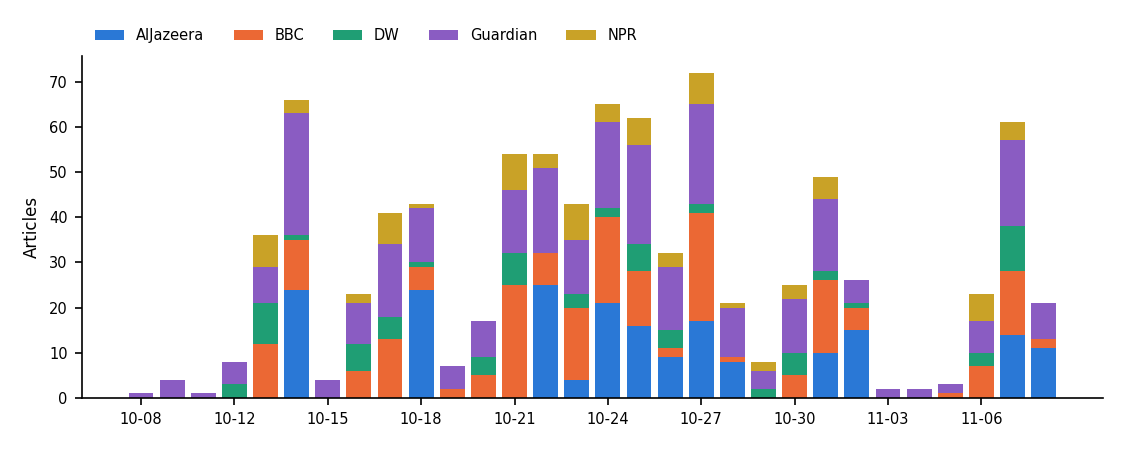

In [31]:
run("python src/14_report_tables.py")
display(Image("results/v2/report/articles_per_day.png"))

## 10 · (Optional) Refresh the replication numbers
The scripts now apply `min_df` per document instead of per topic (see `utils.py` →
`document_level_vectorizer`). Results produced before this fix used fewer topic-unique words,
so re-run the replication with 3 seeds so the report's replication table matches the code in your repo.
This takes roughly 1–2 hours on a T4. Skip it if time is short and say so in the report.

In [26]:
REFRESH_REPLICATION = True
if REFRESH_REPLICATION:
    for k in [10, 50]:
        for s in SEEDS:
            run(f"python src/01_reproduce_original.py --nr_topics {k} --seed {s}{OFF}")
            run(f"python src/06_trumps_tweets.py --nr_topics {k} --seed {s}{OFF}")
    for s in SEEDS:
        run(f"python src/05_bbc_news.py --nr_topics 5 --seed {s}{OFF}")
        run(f"python src/02_new_existing_dataset.py --seed {s}{OFF}")
    for f in ["20newsgroups", "bbcnews", "trumptweets"]:
        p = f"results/{f}_sweep_summary.csv"
        if os.path.isfile(p):
            d = pd.read_csv(p)
            print(f, "\n", d.groupby("nr_topics_requested")[["npmi_coherence", "topic_diversity", "nr_topics_found"]]
                  .agg(["mean", "std"]).round(3).to_string())

$ python src/01_reproduce_original.py --nr_topics 10 --seed 1
[1/4] Loading 20 Newsgroups (same dataset family used in the paper)...
    -> 18211 documents loaded.
[2/4] Fitting BERTopic (embed -> reduce -> cluster -> label)...
[3/4] Computing evaluation metrics (NPMI coherence, topic diversity)...
    -> Average NPMI coherence: 0.2168
    -> Topic diversity:        0.9222
    -> Number of topics found: 9 (plus one outlier group)
[4/4] Saving results...
    -> Saved results/20newsgroups_topic_barchart_k10.html

Done. See results/20newsgroups_topics_k10.csv, results/20newsgroups_metrics_k10.txt, and the running comparison table at results/20newsgroups_sweep_summary.csv
$ python src/06_trumps_tweets.py --nr_topics 10 --seed 1
[1/5] Downloading / loading tweets for years: [2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018]...
    -> Downloading 2009...
    -> Downloading 2010...
    -> Downloading 2011...
    -> Downloading 2012...
    -> Downloading 2013...
    -> Downloading 20

### 10b · LLM-as-judge on the replication and Amazon topics
Same 1–3 interpretability question as Step 8, so the judge's view of the new data can be compared with the original datasets (the brief asks how new results relate to the replication). Uses the topic files written by Step 10 (the last seed run for each setting).

In [27]:
prov = "mock" if OFFLINE_TEST else JUDGE_PROVIDER
import glob
extra = [f for f in glob.glob("results/*_topics_*.csv")]
print(len(extra), "topic files:", extra)
if extra and REFRESH_REPLICATION:   # only judge topics made with the fixed code
    run(f"python src/15_llm_judge.py --provider {prov} --extra_only --extra \"results/*_topics_*.csv\"")
    print(pd.read_csv("results/v2/llm_judge/llm_judge_summary_extra.csv").to_string())

5 topic files: ['results/20newsgroups_topics_k10.csv', 'results/trumptweets_topics_k10.csv', 'results/20newsgroups_topics_k50.csv', 'results/trumptweets_topics_k50.csv', 'results/bbcnews_topics_k5.csv']
$ python src/15_llm_judge.py --provider hf --extra_only --extra "results/*_topics_*.csv"
Judge: hf / Qwen/Qwen2.5-3B-Instruct  |  5 run(s)
  20newsgroups_topics_k10: mean rating 2.11
  20newsgroups_topics_k50: mean rating 2.57
  bbcnews_topics_k5: mean rating 2.75
  trumptweets_topics_k10: mean rating 2.56
  trumptweets_topics_k50: mean rating 2.65

Saved per-topic judgements and results/v2/llm_judge/llm_judge_summary_extra.csv
                       run                        judge  topics_judged  mean_rating  share_rating_3
0  20newsgroups_topics_k10  hf:Qwen/Qwen2.5-3B-Instruct              9        2.111           0.222
1  20newsgroups_topics_k50  hf:Qwen/Qwen2.5-3B-Instruct             49        2.571           0.633
2        bbcnews_topics_k5  hf:Qwen/Qwen2.5-3B-Instruct          

In [33]:
for s in SEEDS:
    run(f"python src/02_new_existing_dataset.py --seed {s}")
print(pd.read_csv("results/amazon_reviews_sweep_summary.csv").to_string())
run(f"python src/15_llm_judge.py --provider {JUDGE_PROVIDER} --extra_only --extra \"results/*_topics*.csv\"")
run("python src/14_report_tables.py")

$ python src/02_new_existing_dataset.py --seed 1
[1/4] Loading Amazon product reviews (fancyzhx/amazon_polarity, via Hugging Face)...
    -> 2000 reviews loaded.
[2/4] Fitting BERTopic...
[3/4] Computing evaluation metrics...
    -> Average NPMI coherence: 0.1351
    -> Topic diversity:        0.8659
[4/4] Saving results...

Done. See results/amazon_reviews_topics.csv and results/amazon_reviews_metrics.txt
$ python src/02_new_existing_dataset.py --seed 2
[1/4] Loading Amazon product reviews (fancyzhx/amazon_polarity, via Hugging Face)...
    -> 2000 reviews loaded.
[2/4] Fitting BERTopic...
[3/4] Computing evaluation metrics...
    -> Average NPMI coherence: 0.1326
    -> Topic diversity:        0.8650
[4/4] Saving results...

Done. See results/amazon_reviews_topics.csv and results/amazon_reviews_metrics.txt
$ python src/02_new_existing_dataset.py --seed 3
[1/4] Loading Amazon product reviews (fancyzhx/amazon_polarity, via Hugging Face)...
    -> 2000 reviews loaded.
[2/4] Fitting BERT

## 11 · Download all results

In [32]:
import shutil
shutil.make_archive("/content/results_v2", "zip", "results")
if IN_COLAB:
    from google.colab import files
    files.download("/content/results_v2.zip")
print(open("results/v2/report/REPORT_NUMBERS.md").read()[:3000])

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Report numbers (generated by src/14_report_tables.py)

## Dataset overview

| Property                        | Value                   |
|:--------------------------------|:------------------------|
| Articles (clean)                | 874                     |
| Articles (raw, before cleaning) | 897                     |
| Outlets                         | 5                       |
| Days with articles              | 30                      |
| First / last day                | 2026-10-08 / 2026-11-08 |
| Mean words per article (full)   | 60.4                    |
| Mean words per article (capped) | 32.5                    |
| Collection runs                 | 10                      |
| Feed fetches that failed        | 6                       |

## Per-outlet profile

| outlet    |   articles |   days |   words_full |   words_capped | feed_success   |
|:----------|-----------:|-------:|-------------:|---------------:|:---------------|
| AlJazeera |        198 |     13 |         25

In [4]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/COMP8240_project
!pip -q install tabulate

!python src/09_annotation_sheet.py --status
!python src/10_annotation_agreement.py
!python src/13_evaluate_event_vs_outlet.py
!python src/16_judge_vs_labels.py
!python src/14_report_tables.py
!python src/17_figures.py

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/COMP8240_project
A (you): 274/274 labelled (100%)
    distinct events: 149 | events with 2+ articles: 39 | events covered by 2+ outlets: 34
B (second annotator): 75/75 labelled (100%)
    distinct events: 40 | events with 2+ articles: 16 | events covered by 2+ outlets: 14
Inter-annotator agreement (v2 event labels)
Articles labelled by both annotators: 75
Article pairs compared:               2775
'Same event' pairs  A: 92  B: 88  both: 88
Cohen's kappa (pairwise same-event):  0.977
Adjusted Rand Index (A vs B):         0.977

Disagreements (first 15) -- discuss these and refine the guideline:
  [A says SAME, B says DIFFERENT]
     Guardian  Mystery over source of Ebola infection in Nigeria fuels concern about spread of virus
     AlJazeera WHO announces start of Ebola vaccine clinical trial in DR Congo
  [A says SAME, B says DIFFERENT]

In [5]:
   !python src/16_judge_vs_labels.py
   !python src/14_report_tables.py
   !python src/17_figures.py
   !cd results && zip -qr /content/results_final.zip . && echo done
   from google.colab import files; files.download("/content/results_final.zip")

python3: can't open file '/content/drive/MyDrive/COMP8240_project/src/16_judge_vs_labels.py': [Errno 2] No such file or directory
Traceback (most recent call last):
  File "/content/drive/MyDrive/COMP8240_project/src/14_report_tables.py", line 224, in <module>
    main()
    ~~~~^^
  File "/content/drive/MyDrive/COMP8240_project/src/14_report_tables.py", line 207, in main
    dataset_tables()
    ~~~~~~~~~~~~~~^^
  File "/content/drive/MyDrive/COMP8240_project/src/14_report_tables.py", line 98, in dataset_tables
    to_tex(prof, os.path.join(OUT, "outlet_profile.tex"),
    ~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
           "Per-outlet profile. Words are mean words per article before (full) and after "
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
           "(capped) length control.", "tab:outlets")
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/drive/MyDrive/COMP8240_project/src/14_report_tables.py", li

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>